**Generative AI Use**: For the purposes of the assignments, the use of generative AI is subject to the same policies regarding collaboration. Just as with other collaborators, each student must write down the solutions independently of the output of the interaction and the submission should include a note denoting the nature of the collaboration. The use of generative AI tools to substantially complete sections of the assignments is not in line with the spirit of the assignments, and would be a violation of the [Honor Code](https://communitystandards.stanford.edu/policies-and-guidance/honor-code).

---

**中文对照（参考译文，不含解答）**

**生成式 AI 的使用**：本作业对生成式 AI 的使用采用与协作相同的规则。与其他协作者交流之后，每位学生仍须独立写出自己的解答，不能直接依赖交流中得到的输出；提交时应附上说明，如实记录协作的性质。使用生成式 AI 实质性地完成作业的大部分内容，不符合本作业的教学目的，也会违反[学术诚信准则](https://communitystandards.stanford.edu/policies-and-guidance/honor-code)。

In [1]:
# CS231n local environment setup (exercise code unchanged)
# [中文] CS231n 本地环境设置。
from pathlib import Path
import os
import sys

_candidates = [Path.cwd(), *Path.cwd().parents]
_workspace = next((p for p in _candidates if (p / "requirements-local.txt").is_file()
                   and (p / "assignment1" / "cs231n").is_dir()), None)
if _workspace is None:
    raise RuntimeError("Launch Jupyter from the CS231n workspace root.")
ASSIGNMENT_DIR = _workspace / "assignment1"
os.chdir(ASSIGNMENT_DIR)
if str(ASSIGNMENT_DIR) not in sys.path:
    sys.path.insert(0, str(ASSIGNMENT_DIR))
print("Python:", sys.executable)
print("Working directory:", Path.cwd())


Python: D:\cs231n\.venv\Scripts\python.exe
Working directory: D:\cs231n\assignment1


# Fully-Connected Neural Nets
In this exercise we will implement fully-connected networks using a modular approach. For each layer we will implement a `forward` and a `backward` function. The `forward` function will receive inputs, weights, and other parameters and will return both an output and a `cache` object storing data needed for the backward pass, like this:

```python
def layer_forward(x, w):
  """ Receive inputs x and weights w """
  # Do some computations ...
  z = # ... some intermediate value
  # Do some more computations ...
  out = # the output
   
  cache = (x, w, z, out) # Values we need to compute gradients
   
  return out, cache
```

The backward pass will receive upstream derivatives and the `cache` object, and will return gradients with respect to the inputs and weights, like this:

```python
def layer_backward(dout, cache):
  """
  Receive dout (derivative of loss with respect to outputs) and cache,
  and compute derivative with respect to inputs.
  """
  # Unpack cache values
  x, w, z, out = cache
  
  # Use values in cache to compute derivatives
  dx = # Derivative of loss with respect to x
  dw = # Derivative of loss with respect to w
  
  return dx, dw
```

After implementing a bunch of layers this way, we will be able to easily combine them to build classifiers with different architectures.
  

---

**中文对照（参考译文，不含解答）**

# 全连接神经网络

采用模块化方式搭建网络：每层提供 forward 和 backward。前向传播返回输出 out，同时把反向传播需要的输入、权重和中间结果保存为 cache；反向传播接收上游梯度 dout 和 cache，计算损失对输入及参数的梯度。英文原文中的两段示例仅说明这一接口结构，保留原样。按这一约定实现基础层后，就可以组合成不同结构的网络。

In [2]:
# As usual, a bit of setup
# [中文] 执行必要的环境与导入设置。
from __future__ import print_function
import time
import numpy as np
import matplotlib.pyplot as plt
from cs231n.classifiers.fc_net import *
from cs231n.data_utils import get_CIFAR10_data
from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
# [中文] 设置图像的默认显示大小。
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# for auto-reloading external modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
# [中文] 启用外部模块自动重载；相关说明见英文注释中的链接。
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """ returns relative error """
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

In [3]:
# Load the (preprocessed) CIFAR10 data.
# [中文] 加载预处理后的 CIFAR-10 数据。

data = get_CIFAR10_data()
for k, v in list(data.items()):
  print(('%s: ' % k, v.shape))

('X_train: ', (49000, 3, 32, 32))
('y_train: ', (49000,))
('X_val: ', (1000, 3, 32, 32))
('y_val: ', (1000,))
('X_test: ', (1000, 3, 32, 32))
('y_test: ', (1000,))


# Affine layer: forward
Open the file `cs231n/layers.py` and implement the `affine_forward` function.

Once you are done you can test your implementaion by running the following:

---

**中文对照（参考译文，不含解答）**

# 仿射层：前向传播

打开 cs231n/layers.py，实现 affine_forward，然后运行下方单元检查输出。

In [5]:
# Test the affine_forward function
# [中文] 测试 affine_forward 函数。

num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])

# Compare your output with ours. The error should be around e-9 or less.
# [中文] 与参考输出比较，误差应约为 1e-9 或更小。
print('Testing affine_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing affine_forward function:
difference:  9.769848888397517e-10


# Affine layer: backward
Now implement the `affine_backward` function and test your implementation using numeric gradient checking.

---

**中文对照（参考译文，不含解答）**

# 仿射层：反向传播

实现 affine_backward，并用数值梯度检查结果。

In [7]:
# Test the affine_backward function
# [中文] 测试 affine_backward 函数。
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

# The error should be around e-10 or less
# [中文] 误差应约为 1e-10 或更小。
print('Testing affine_backward function:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_backward function:
dx error:  5.399100368651805e-11
dw error:  9.904211865398145e-11
db error:  2.4122867568119087e-11


# ReLU activation: forward
Implement the forward pass for the ReLU activation function in the `relu_forward` function and test your implementation using the following:

---

**中文对照（参考译文，不含解答）**

# ReLU：前向传播

在 relu_forward 中实现 ReLU 的前向计算，再运行下方检查。

In [11]:
# Test the relu_forward function
# [中文] 测试 relu_forward 函数。

x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# Compare your output with ours. The error should be on the order of e-8
# [中文] 与参考输出比较，误差应在 1e-8 量级。
print('Testing relu_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing relu_forward function:
difference:  4.999999798022158e-08


# ReLU activation: backward
Now implement the backward pass for the ReLU activation function in the `relu_backward` function and test your implementation using numeric gradient checking:

---

**中文对照（参考译文，不含解答）**

# ReLU：反向传播

在 relu_backward 中实现反向传播，并进行数值梯度检查。

In [12]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# The error should be on the order of e-12
# [中文] 误差应在 1e-12 量级。
print('Testing relu_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing relu_backward function:
dx error:  3.2756349136310288e-12


## Inline Question 1:

We've only asked you to implement ReLU, but there are a number of different activation functions that one could use in neural networks, each with its pros and cons. In particular, an issue commonly seen with activation functions is getting zero (or close to zero) gradient flow during backpropagation. Which of the following activation functions have this problem? If you consider these functions in the one dimensional case, what types of input would lead to this behaviour?
1. Sigmoid
2. ReLU
3. Leaky ReLU

$\color{blue}{\textit Your Answer:}$ *Fill this in*




---

**中文对照（参考译文，不含解答）**

## 随堂问题 1

本题只要求实现 ReLU，但神经网络还可以使用多种激活函数，各有优缺点。激活函数的一个常见问题是，在反向传播时梯度变为零或接近零。下列哪些激活函数会出现这个问题？在一维情况下，哪些类型的输入会导致这种现象？

1. Sigmoid
2. ReLU
3. Leaky ReLU

**你的回答：** ReLU和Sigmoid都会。
输入各元素都小于0时，ReLU会；输入绝对值很大时，Sigmoid会进入饱和区，局部梯度接近0；而Leaky ReLU在相比ReLU，在负数区域会保留一个小的非零斜率，可以避免局部梯度直接变为0.

# "Sandwich" layers
There are some common patterns of layers that are frequently used in neural nets. For example, affine layers are frequently followed by a ReLU nonlinearity. To make these common patterns easy, we define several convenience layers in the file `cs231n/layer_utils.py`.

For now take a look at the `affine_relu_forward` and `affine_relu_backward` functions, and run the following to numerically gradient check the backward pass:

---

**中文对照（参考译文，不含解答）**

# 常用组合层

神经网络常把仿射层与 ReLU 等层连接使用。cs231n/layer_utils.py 提供了封装这些常见组合的便利函数。阅读 affine_relu_forward、affine_relu_backward，并运行下方数值梯度检查。

In [13]:
from cs231n.layer_utils import affine_relu_forward, affine_relu_backward
np.random.seed(231)
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)

# Relative error should be around e-10 or less
# [中文] 相对误差应约为 1e-10 或更小。
print('Testing affine_relu_forward and affine_relu_backward:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_relu_forward and affine_relu_backward:
dx error:  2.299579177309368e-11
dw error:  8.162011105764925e-11
db error:  7.826724021458994e-12


# Loss layers: Softmax
Now implement the loss and gradient for softmax in the `softmax_loss` function in `cs231n/layers.py`. These should be similar to what you implemented in `cs231n/classifiers/softmax.py`. Other loss functions (e.g. `svm_loss`) can also be implemented in a modular way, however, it is not required for this assignment.

You can make sure that the implementations are correct by running the following:

---

**中文对照（参考译文，不含解答）**

# 损失层：Softmax

在 cs231n/layers.py 的 softmax_loss 中实现 Softmax 损失及梯度，思路与此前分类器中的实现类似。其他损失也可模块化封装，但本作业不要求实现 svm_loss。完成后运行下方检查。

In [17]:
np.random.seed(231)
num_classes, num_inputs = 10, 50
x = 0.001 * np.random.randn(num_inputs, num_classes)
y = np.random.randint(num_classes, size=num_inputs)


dx_num = eval_numerical_gradient(lambda x: softmax_loss(x, y)[0], x, verbose=False)
loss, dx = softmax_loss(x, y)

# Test softmax_loss function. Loss should be close to 2.3 and dx error should be around e-8
# [中文] 测试 softmax_loss：损失应接近 2.3，dx 的相对误差应在 1e-8 量级。
print('\nTesting softmax_loss:')
print('loss: ', loss)
print('dx error: ', rel_error(dx_num, dx))


Testing softmax_loss:
loss:  2.3025458445007376
dx error:  8.234144091578429e-09


# Two-layer network
Open the file `cs231n/classifiers/fc_net.py` and complete the implementation of the `TwoLayerNet` class. Read through it to make sure you understand the API. You can run the cell below to test your implementation.

---

**中文对照（参考译文，不含解答）**

# 双层网络

打开 cs231n/classifiers/fc_net.py，补全 TwoLayerNet。阅读接口说明，确认输入输出约定，再运行下方检查。

In [18]:
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)

print('Testing initialization ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'First layer weights do not seem right'
assert np.all(b1 == 0), 'First layer biases do not seem right'
assert W2_std < std / 10, 'Second layer weights do not seem right'
assert np.all(b2 == 0), 'Second layer biases do not seem right'

print('Testing test-time forward pass ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray(
  [[11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]])
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Problem with test-time forward pass'

print('Testing training loss (no regularization)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Problem with training-time loss'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Problem with regularization loss'

# Errors should be around e-7 or less
# [中文] 误差应约为 1e-7 或更小。
for reg in [0.0, 0.7]:
  print('Running numeric gradient check with reg = ', reg)
  model.reg = reg
  loss, grads = model.loss(X, y)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Testing initialization ... 
Testing test-time forward pass ... 
Testing training loss (no regularization)
Running numeric gradient check with reg =  0.0
W1 relative error: 1.52e-08
W2 relative error: 3.21e-10
b1 relative error: 8.37e-09
b2 relative error: 4.33e-10
Running numeric gradient check with reg =  0.7
W1 relative error: 2.53e-07
W2 relative error: 2.85e-08
b1 relative error: 1.56e-08
b2 relative error: 7.76e-10


# Solver
Open the file `cs231n/solver.py` and read through it to familiarize yourself with the API. After doing so, use a `Solver` instance to train a `TwoLayerNet` that achieves about `36%` accuracy on the validation set.

---

**中文对照（参考译文，不含解答）**

# Solver：训练过程管理

阅读 cs231n/solver.py，熟悉 Solver 的接口；随后用它训练 TwoLayerNet，参考目标为验证准确率约 36%。

In [21]:
input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
model = TwoLayerNet(input_size, hidden_size, num_classes)
solver = None

##############################################################################
# TODO: Use a Solver instance to train a TwoLayerNet that achieves about 36% #
# accuracy on the validation set.                                            #
##############################################################################
# [中文] 待完成：使用 Solver 训练 TwoLayerNet，题目参考目标是验证准确率约 36%。
solver = Solver(
    model, 
    data,
    optim_config={"learning_rate": 1e-3},
    print_every=1000
)
solver.train()
##############################################################################
#                             END OF YOUR CODE                               #
##############################################################################
# [中文] 自行实现的代码区域结束。


(Iteration 1 / 4900) loss: 2.300623
(Epoch 0 / 10) train acc: 0.113000; val_acc: 0.112000
(Epoch 1 / 10) train acc: 0.441000; val_acc: 0.423000
(Epoch 2 / 10) train acc: 0.491000; val_acc: 0.490000
(Iteration 1001 / 4900) loss: 1.517609
(Epoch 3 / 10) train acc: 0.504000; val_acc: 0.487000
(Epoch 4 / 10) train acc: 0.490000; val_acc: 0.485000
(Iteration 2001 / 4900) loss: 1.481616
(Epoch 5 / 10) train acc: 0.519000; val_acc: 0.479000
(Epoch 6 / 10) train acc: 0.541000; val_acc: 0.473000
(Iteration 3001 / 4900) loss: 1.396591
(Epoch 7 / 10) train acc: 0.555000; val_acc: 0.493000
(Epoch 8 / 10) train acc: 0.534000; val_acc: 0.483000
(Iteration 4001 / 4900) loss: 1.304305
(Epoch 9 / 10) train acc: 0.572000; val_acc: 0.490000
(Epoch 10 / 10) train acc: 0.543000; val_acc: 0.491000


# Debug the training
With the default parameters we provided above, you should get a validation accuracy of about 0.36 on the validation set. This isn't very good.

One strategy for getting insight into what's wrong is to plot the loss function and the accuracies on the training and validation sets during optimization.

Another strategy is to visualize the weights that were learned in the first layer of the network. In most neural networks trained on visual data, the first layer weights typically show some visible structure when visualized.

---

**中文对照（参考译文，不含解答）**

# 调试训练过程

默认参数的验证准确率约为 0.36，仍有改进空间。可以观察损失随迭代次数的变化，以及训练、验证准确率曲线，分析训练过程；也可以可视化第一层权重，查看是否学到了可辨认的结构。

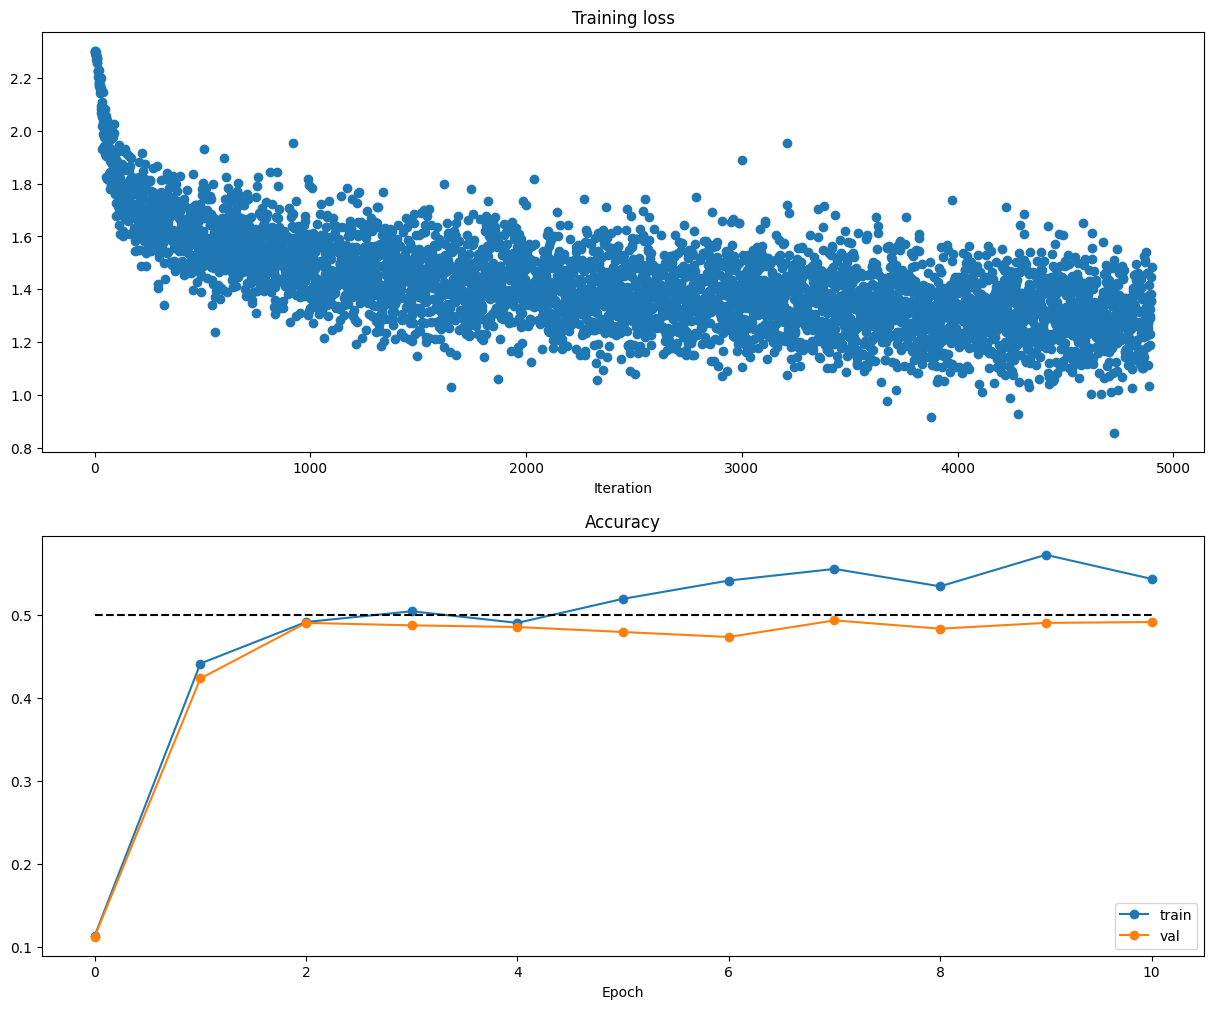

In [22]:
# Run this cell to visualize training loss and train / val accuracy
# [中文] 运行此单元，查看训练损失和训练、验证准确率曲线。

plt.subplot(2, 1, 1)
plt.title('Training loss')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Iteration')

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(solver.train_acc_history, '-o', label='train')
plt.plot(solver.val_acc_history, '-o', label='val')
plt.plot([0.5] * len(solver.val_acc_history), 'k--')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

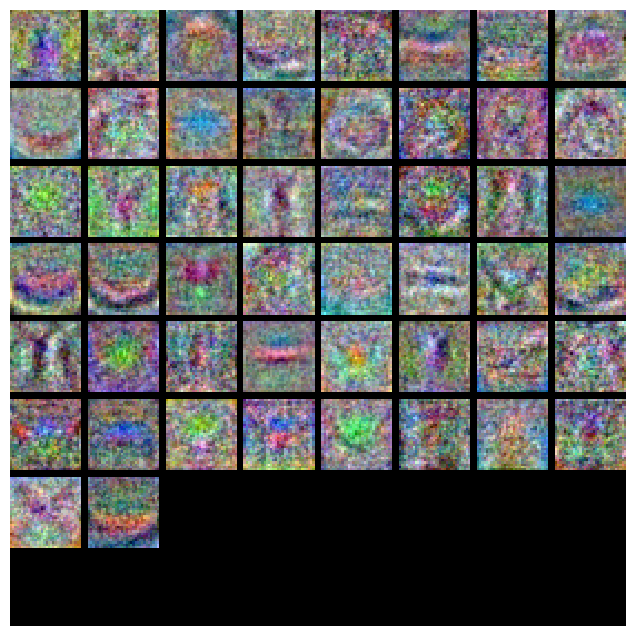

In [23]:
from cs231n.vis_utils import visualize_grid

# Visualize the weights of the network
# [中文] 可视化网络权重。

def show_net_weights(net):
    W1 = net.params['W1']
    W1 = W1.reshape(3, 32, 32, -1).transpose(3, 1, 2, 0)
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.gca().axis('off')
    plt.show()

show_net_weights(model)

# Tune your hyperparameters

**What's wrong?**. Looking at the visualizations above, we see that the loss is decreasing more or less linearly, which seems to suggest that the learning rate may be too low. Moreover, there is no gap between the training and validation accuracy, suggesting that the model we used has low capacity, and that we should increase its size. On the other hand, with a very large model we would expect to see more overfitting, which would manifest itself as a very large gap between the training and validation accuracy.

**Tuning**. Tuning the hyperparameters and developing intuition for how they affect the final performance is a large part of using Neural Networks, so we want you to get a lot of practice. Below, you should experiment with different values of the various hyperparameters, including hidden layer size, learning rate, numer of training epochs, and regularization strength. You might also consider tuning the learning rate decay, but you should be able to get good performance using the default value.

**Approximate results**. You should be aim to achieve a classification accuracy of greater than 48% on the validation set. Our best network gets over 52% on the validation set.

**Experiment**: You goal in this exercise is to get as good of a result on CIFAR-10 as you can (52% could serve as a reference), with a fully-connected Neural Network. Feel free implement your own techniques (e.g. PCA to reduce dimensionality, or adding dropout, or adding features to the solver, etc.).

---

**中文对照（参考译文，不含解答）**

# 调节超参数

上方示例中损失下降较慢，可能提示学习率偏低；训练与验证准确率都不高且差距很小，可能提示模型容量不足。模型过大时则可能过拟合，表现为训练准确率明显高于验证准确率。请在验证集上尝试隐藏层大小、学习率、epoch 数和正则化强度，也可调整学习率衰减；默认衰减值通常已可用。要求验证准确率超过 48%，课程参考模型超过 52%。PCA、Dropout 或扩展 Solver 等属于可自行探索的方向。

In [24]:
best_model = None



#################################################################################
# TODO: Tune hyperparameters using the validation set. Store your best trained  #
# model in best_model.                                                          #
#                                                                               #
# To help debug your network, it may help to use visualizations similar to the  #
# ones we used above; these visualizations will have significant qualitative    #
# differences from the ones we saw above for the poorly tuned network.          #
#                                                                               #
# Tweaking hyperparameters by hand can be fun, but you might find it useful to  #
# write code to sweep through possible combinations of hyperparameters          #
# automatically like we did on thexs previous exercises.                          #
#################################################################################
# [中文] 待完成：在验证集上调节超参数，将最佳模型存入
# best_model。可参考前面的损失和准确率曲线进行调试；调参良好的网络与调参不佳的网络会呈现不同的曲线。可以手动调整，也可以像前面一样编写代码搜索候选组合。
best_model = solver.model
################################################################################
#                              END OF YOUR CODE                                #
################################################################################
# [中文] 自行实现的代码区域结束。


# Test your model!
Run your best model on the validation and test sets. You should achieve above 48% accuracy on the validation set and the test set.

---

**中文对照（参考译文，不含解答）**

# 评估模型

在验证集和测试集上运行选出的模型，准确率都应超过 48%。

In [25]:
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
print('Validation set accuracy: ', (y_val_pred == data['y_val']).mean())

Validation set accuracy:  0.493


In [26]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
print('Test set accuracy: ', (y_test_pred == data['y_test']).mean())

Test set accuracy:  0.49


In [27]:
# Save best model
# [中文] 保存验证表现最佳的模型。
best_model.save("best_two_layer_net.npy")

best_two_layer_net.npy saved.


## Inline Question 2:

Now that you have trained a Neural Network classifier, you may find that your testing accuracy is much lower than the training accuracy. In what ways can we decrease this gap? Select all that apply.

1. Train on a larger dataset.
2. Add more hidden units.
3. Increase the regularization strength.
4. None of the above.

$\color{blue}{\textit Your Answer:}$

$\color{blue}{\textit Your Explanation:}$



---

**中文对照（参考译文，不含解答）**

## 随堂问题 2

训练神经网络分类器后，你可能发现测试准确率远低于训练准确率。哪些方法可以减小这个差距？请选择所有适用选项。

1. 使用更大的数据集训练。
2. 增加隐藏单元的数量。
3. 增大正则化强度。
4. 以上都不适用。

**你的回答：** 1、3都可以

**你的解释：** 测试准确率远低于训练准确率，说明出现了过拟合。使用更大的数据集训练有助于提高模型的泛化能力，而适当增大正则化强度也可以减轻过拟合程度。对于增加隐藏单元数量，这会提高模型容量，保存更多测试集特征，可能会加重过拟合。另外，正则化过强还会导致欠拟合。